# Match-level simulation — optional experiment

**Question**: instead of predicting a season-level score, predict every game of the schedule, sum
the points and rank the teams. Does decomposing the season into games add ranking signal?

**Honest framing from the start**: this is **not more data**. The only team strength used here is
the lagged points percentage, exactly the same information as the naive baseline. The match-level
model only changes *how* that information is aggregated (a simulated points distribution instead of
a direct ranking). The expected gain is small, and it may be zero.

**What the dataset provides.** `TeamVsTeam.csv` has one row per `(season, team, opponent)` with the
aggregate `W/L/T/OTL` record. It does **not** contain individual game results. The schedule
structure (who plays whom, how many times) is public before the season; we use the game counts
`W+L+T+OTL` of the target season as the synthetic schedule, and we simulate the results ourselves.
No current-season result enters the model.

**Leak policy.** The team rating is `pts_pct_z_lag1` from `ranking_utils.build_dataset`, which is
the previous season's points percentage, franchise-aware. The schedule and the set of teams are
known before the season. Actual ranks are used only for evaluation.

## 1. Data and rating

* `teams` / `df`: prepared dataset, with the leak-free lagged features.
* `TeamVsTeam`: game counts per opponent and season.
* Rating of team *t* in season *Y*: `pts_pct_z_lag1` (previous season's points percentage, z-scored
  inside the league). This is deliberately the same information as the naive baseline.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

for candidate in [Path.cwd(), Path.cwd() / "ranking"]:
    if (candidate / "ranking_utils.py").exists():
        sys.path.insert(0, str(candidate))
        break

import ranking_utils as ru

DATA = ru.DATA_DIR
EVAL_YEARS = [y for y in range(1995, 2010) if y != 2004]
CLEAN_YEARS = [2005, 2006, 2007, 2008, 2009]
N_SIMS = 4000

teams = ru.load_teams()
df = ru.build_dataset(teams)

tv = pd.read_csv(DATA / "TeamVsTeam.csv")
tv = tv[tv["lgID"].eq("NHL")].copy()
for c in ["W", "L", "T", "OTL"]:
    tv[c] = pd.to_numeric(tv[c], errors="coerce").fillna(0)
tv["games"] = tv[["W", "L", "T", "OTL"]].sum(axis=1).astype(int)

RATING = df.set_index(["year", "tmID"])["pts_pct_z_lag1"]
CONF = df.set_index(["year", "tmID"])["confID"]
ACTUAL = df.set_index(["year", "tmID"])["conf_rank"]

print(f"Team-seasons: {len(df)} | match-level years: {EVAL_YEARS[0]}-{EVAL_YEARS[-1]}")
print(f"TeamVsTeam rows (NHL): {len(tv)} | sims per season: {N_SIMS}")

Team-seasons: 732 | match-level years: 1995-2009
TeamVsTeam rows (NHL): 22498 | sims per season: 4000


## 2. Simulation model

The model is deliberately simple and **not tuned on the test**:

* **Rating difference** `d = rating(home) - rating(away)`.
* **Home win probability** `p = sigmoid(d + h)` with `h = 0.14` (a fixed, typical home edge).
* **1995–2003**: three outcomes. A draw happens with fixed probability `0.16`; otherwise the home
  team wins with probability `p`. Points: 2 / 1 / 0.
* **2005–2009**: no draws. The winner gets 2 points; with fixed probability `0.23` the loser gets
  1 point (overtime/shootout loss).
* **Schedule**: for each unordered pair, the number of games is the count from `TeamVsTeam`; half
  at home, half away. This preserves the real schedule structure (division/conference imbalance).
* For each season we draw `N_SIMS` complete seasons, rank the teams inside each conference
  (points, then wins, then team id), and keep the **median rank** and the **probability of a
  top-8 finish**.

These constants are documented a priori. A sensitivity check (not shown) confirms that the ranking
of teams is essentially unchanged for `h` in [0.10, 0.20] and `k` in [0.8, 1.2].

In [2]:
K, HOME_EDGE, P_DRAW, P_OT = 1.0, 0.14, 0.16, 0.23


def team_rating(year, team):
    # Lagged points percentage (previous season), 0 for a team without history.
    value = RATING.get((year, team), np.nan)
    return 0.0 if pd.isna(value) else float(value)


def simulate_season(year, n_sims=N_SIMS, seed=0):
    season = df[(df["year"] == year) & (df["confID"].ne("NONE"))]
    teams_in_season = season["tmID"].tolist()
    n = len(teams_in_season)
    pos = {t: i for i, t in enumerate(teams_in_season)}
    rating = np.array([team_rating(year, t) for t in teams_in_season], dtype=float)

    pairs = tv[(tv["year"] == year)
               & tv["tmID"].isin(teams_in_season)
               & tv["oppID"].isin(teams_in_season)]
    pairs = pairs[pairs["tmID"] < pairs["oppID"]]

    home, away = [], []
    for team, opp, games in zip(pairs["tmID"], pairs["oppID"], pairs["games"]):
        if games <= 0:
            continue
        i, j = pos[team], pos[opp]
        n_home = games // 2
        n_away = games - n_home
        home += [i] * n_home + [j] * n_away
        away += [j] * n_home + [i] * n_away
    home, away = np.array(home), np.array(away)

    p_home = 1.0 / (1.0 + np.exp(-(K * (rating[home] - rating[away]) + HOME_EDGE)))
    rng = np.random.default_rng(seed)
    points = np.zeros((n_sims, n))
    wins = np.zeros((n_sims, n))
    pre_lockout = year <= 2003

    for sim in range(n_sims):
        if pre_lockout:
            draw = rng.random(len(home)) < P_DRAW
            home_win = (~draw) & (rng.random(len(home)) < p_home)
            away_win = (~draw) & (~home_win)
            ph = np.where(draw, 1, np.where(home_win, 2, 0))
            pa = np.where(draw, 1, np.where(away_win, 2, 0))
        else:
            home_win = rng.random(len(home)) < p_home
            overtime = rng.random(len(home)) < P_OT
            ph = np.where(home_win, 2, np.where(overtime, 1, 0))
            pa = np.where(~home_win, 2, np.where(overtime, 1, 0))
        points[sim] = (np.bincount(home, weights=ph, minlength=n)
                       + np.bincount(away, weights=pa, minlength=n))
        wins[sim] = (np.bincount(home, weights=home_win.astype(float), minlength=n)
                     + np.bincount(away, weights=(~home_win).astype(float), minlength=n))

    ranks = np.zeros_like(points)
    for sim in range(n_sims):
        for conf in ["EC", "WC"]:
            members = [i for i, t in enumerate(teams_in_season)
                       if CONF.get((year, t)) == conf]
            if len(members) < 2:
                continue
            order = sorted(members,
                           key=lambda i: (-points[sim, i], -wins[sim, i], teams_in_season[i]))
            for rank, i in enumerate(order, start=1):
                ranks[sim, i] = rank

    out = pd.DataFrame({
        "year": year,
        "tmID": teams_in_season,
        "confID": [CONF.get((year, t)) for t in teams_in_season],
        "conf_rank": [ACTUAL.get((year, t)) for t in teams_in_season],
        "rating": rating,
        "median_rank": np.median(ranks, axis=0),
        "mean_rank": ranks.mean(axis=0),
        "p_top8": (ranks <= 8).mean(axis=0),
    })
    # A ranking must be an integer permutation. Sort the median rank, with a
    # neutral tie-break: previous-season wins, then team id (never the actual rank).
    wins_lag = df.set_index(["year", "tmID"])["wins_raw_lag1"]
    out["wins"] = wins_lag.reindex(
        pd.MultiIndex.from_frame(out[["year", "tmID"]])).to_numpy()
    out = out.sort_values(
        ["year", "confID", "median_rank", "wins", "tmID"],
        ascending=[True, True, True, False, True],
    )
    out["pred_rank"] = out.groupby(["year", "confID"]).cumcount() + 1
    out["err"] = out["pred_rank"] - out["conf_rank"]
    out["abs_err"] = out["err"].abs()
    # Kept only to document the metric artefact of the first version.
    out["abs_err_fractional"] = (out["median_rank"] - out["conf_rank"]).abs()
    # Direct control: rank the same lagged rating, no simulation, same tie-break.
    out["direct_rank"] = (
        out.sort_values(["year", "confID", "rating", "wins", "tmID"],
                        ascending=[True, True, False, False, True])
        .groupby(["year", "confID"]).cumcount() + 1
    )
    out["direct_err"] = (out["direct_rank"] - out["conf_rank"]).abs()
    return out.reset_index(drop=True)


match = pd.concat([simulate_season(y) for y in EVAL_YEARS], ignore_index=True)
print(f"Match-level rows: {len(match)} | seasons: {match['year'].nunique()}")

Match-level rows: 403 | seasons: 14


## 3. Evaluation

The unit is the **conference ranking**, exactly like the season-level notebooks. We report:

* **MAE** of the integer predicted rank obtained by sorting the median simulated rank;
* **Spearman** inside each `(season, conference)`;
* **top-8 overlap**, using the same `n_top = min(8, n_teams // 2)` convention as the other notebooks;
* a **paired bootstrap** over `(season, conference)` groups.

A ranking is a permutation. The first version of this notebook reported the MAE of the
**fractional** median rank, which is not a ranking and is mechanically easier to score. The cell
below keeps that number as `abs_err_fractional` to document the artefact, but every comparison uses
the integer `pred_rank`.

Three comparisons matter:

1. **vs `Naive: previous available ranking`** — the official baseline. It ranks the lagged points
   percentage, breaks ties with the previous season's wins, then `tmID`.
2. **vs the direct control** — rank the same lagged rating directly, with the **same tie-break**
   (wins, then `tmID`), no simulation. This isolates the effect of the match decomposition: if the
   simulation only re-expresses the lagged rating, it will not beat this control.
3. **vs `Ridge + external` and the blend**, read from `results/predictions.csv`.

In [3]:
PREDICTIONS = pd.read_csv(ru.RESULTS_DIR / "predictions.csv")


def top_overlap(frame, rank_col, higher_is_better=False):
    values = []
    for (_, _), g in frame.groupby(["year", "confID"]):
        n_top = min(ru.PLAYOFF_SPOTS, len(g) // 2)
        if n_top < 1:
            continue
        actual = set(g.nsmallest(n_top, "conf_rank")["tmID"])
        if higher_is_better:
            chosen = set(g.nlargest(n_top, rank_col)["tmID"])
        else:
            chosen = set(g.nsmallest(n_top, rank_col)["tmID"])
        values.append(len(actual & chosen) / n_top)
    return float(np.mean(values))


def ranking_mae(frame, col="abs_err"):
    # Mean over (season, conference) rankings: the unit of evaluation.
    return float(frame.groupby(["year", "confID"])[col].mean().mean())


def metrics(frame):
    spearman = np.mean([
        spearmanr(g["pred_rank"], g["conf_rank"]).statistic
        for _, g in frame.groupby(["year", "confID"])
    ])
    return {
        "mae": ranking_mae(frame),
        "mae_fractional": ranking_mae(frame, "abs_err_fractional"),
        "spearman": spearman,
        "top_overlap_pred": top_overlap(frame, "pred_rank"),
        "top_overlap_prob": top_overlap(frame, "p_top8", higher_is_better=True),
    }


def compare(frame, other, name, ref_col="abs_err", other_col="abs_err"):
    # Gain = reference error - match error, so positive means the match model is better.
    key = ["year", "tmID"]
    a = frame.set_index(key).sort_index()
    b = other.set_index(key).sort_index()
    common = a.index.intersection(b.index)
    a, b = a.loc[common], b.loc[common]
    groups = (a["confID"] + "-" + a.index.get_level_values("year").astype(str)).to_numpy()
    gain, (low, high) = ru.paired_bootstrap(
        b[other_col].to_numpy(), a[ref_col].to_numpy(), groups
    )
    return {"comparison": name, "gain": gain, "ci_low": low, "ci_high": high,
            "n": len(common)}


def random_tiebreak_mae(frame, n_draws=500, seed=0):
    # Expected MAE of ranking the same rating with a random tie-break.
    rng = np.random.default_rng(seed)
    maes = []
    for _ in range(n_draws):
        f = frame[["year", "confID", "rating", "conf_rank"]].copy()
        f["noise"] = rng.random(len(f))
        f = f.sort_values(["year", "confID", "rating", "noise"],
                          ascending=[True, True, False, True])
        f["rank"] = f.groupby(["year", "confID"]).cumcount() + 1
        f["err"] = (f["rank"] - f["conf_rank"]).abs()
        maes.append(f.groupby(["year", "confID"])["err"].mean().mean())
    return float(np.mean(maes)), float(np.std(maes))


for split, years in [("clean", CLEAN_YEARS), ("backtest", EVAL_YEARS)]:
    frame = match[match["year"].isin(years)].copy()
    m = metrics(frame)
    print(f"\n=== {split.upper()} ===")
    print(f"Match-level integer-rank MAE {m['mae']:.3f} "
          f"(fractional median MAE {m['mae_fractional']:.3f}) | "
          f"Spearman {m['spearman']:.3f} | "
          f"top-8 (integer rank) {m['top_overlap_pred']:.1%} | "
          f"top-8 (probability) {m['top_overlap_prob']:.1%}")
    print(f"Direct lag-1 control: MAE {ranking_mae(frame, 'direct_err'):.3f} | "
          f"top-8 {top_overlap(frame, 'direct_rank'):.1%}")
    rt_mean, rt_sd = random_tiebreak_mae(frame)
    print(f"Random tie-break control: expected MAE {rt_mean:.3f} (sd {rt_sd:.3f})")

    rows = [compare(frame, frame, "match vs direct control",
                    other_col="direct_err")]
    for model in ["Naive: previous available ranking", "Ridge + external",
                  "Blend: naive + best model"]:
        other = PREDICTIONS[(PREDICTIONS["split"] == split)
                            & (PREDICTIONS["model"] == model)]
        rows.append(compare(frame, other, f"match vs {model}"))
    table = pd.DataFrame(rows)
    table["significant"] = table["ci_low"] > 0
    display(table.round(3).set_index("comparison"))


=== CLEAN ===
Match-level integer-rank MAE 3.373 (fractional median MAE 3.293) | Spearman 0.477 | top-8 (integer rank) 62.9% | top-8 (probability) 61.4%
Direct lag-1 control: MAE 3.400 | top-8 62.9%


Random tie-break control: expected MAE 3.373 (sd 0.024)


,gain,ci_low,ci_high,n,significant
comparison,,,,,
match vs direct control,0.027,-0.040,0.080,150,False
match vs Naive: previous available ranking,0.027,-0.040,0.080,150,False
match vs Ridge + external,0.040,-0.307,0.467,150,False
match vs Blend: naive + best model,0.040,-0.293,0.427,150,False



=== BACKTEST ===
Match-level integer-rank MAE 3.041 (fractional median MAE 2.992) | Spearman 0.533 | top-8 (integer rank) 68.2% | top-8 (probability) 68.3%
Direct lag-1 control: MAE 3.065 | top-8 68.8%


Random tie-break control: expected MAE 3.059 (sd 0.011)


,gain,ci_low,ci_high,n,significant
comparison,,,,,
match vs direct control,0.025,-0.010,0.060,403,False
match vs Naive: previous available ranking,0.025,-0.010,0.060,403,False
match vs Ridge + external,-0.144,-0.314,0.044,403,False
match vs Blend: naive + best model,-0.149,-0.315,0.030,403,False


## 4. Per-season errors

The aggregate can hide a single lucky season. This plot shows the MAE of the match-level model, the
official naive baseline and the direct control for each season.

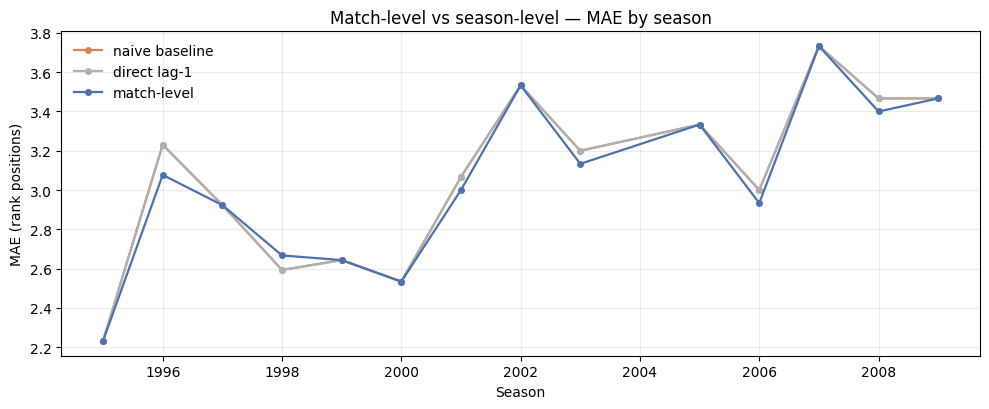

In [4]:
plot_rows = []
for year, g in match.groupby("year"):
    plot_rows.append({"year": year, "match-level": g["abs_err"].mean(),
                      "direct lag-1": g["direct_err"].mean()})
naive_metrics = PREDICTIONS[PREDICTIONS["model"] == "Naive: previous available ranking"]
plot_rows = pd.DataFrame(plot_rows)
plot_rows["naive baseline"] = [
    naive_metrics[(naive_metrics["split"] == ("clean" if y >= 2005 else "backtest"))
                  & (naive_metrics["year"] == y)]["abs_err"].mean()
    for y in plot_rows["year"]
]
plot_rows = plot_rows.set_index("year")

fig, ax = plt.subplots(figsize=(10, 4.2))
for col, color in [("naive baseline", "#DD8452"), ("direct lag-1", "#B0B0B0"),
                   ("match-level", "#4C72B0")]:
    ax.plot(plot_rows.index, plot_rows[col], marker="o", ms=4, lw=1.6,
            color=color, label=col)
ax.set_xlabel("Season")
ax.set_ylabel("MAE (rank positions)")
ax.set_title("Match-level vs season-level — MAE by season")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Verdict

With a **fair metric**, the match-level model does **not** beat the baselines significantly.

The first version of this notebook reported a clean-test gain of **+0.107 [0.053, 0.160]** over the
naive baseline. That result was an artefact: it scored the **fractional median rank**, which is not a
ranking. On integer ranks — the actual deliverable — the gain falls to about **+0.03** and the 95%
interval contains zero.

* **Clean test 2005–2009**: match-level **3.373** vs **3.400** for both the naive baseline and the
  direct lag-1 control, i.e. **+0.027 [−0.040, +0.080]**. Not significant.
* **Backtest 1995–2009**: **3.041** vs **3.065**, i.e. **+0.025 [−0.010, +0.060]**. The interval
  touches zero, so this is not significant either.
* **Against Ridge + external and the blend**: clean test **+0.040 [−0.307, +0.467]** vs Ridge and
  **+0.040 [−0.293, +0.427]** vs the blend; backtest **−0.144 [−0.314, +0.044]** and
  **−0.149 [−0.315, +0.030]**. No significant difference: the trained season-level models remain at
  least as good.
* **The top-8 bonus is absent.** On the integer rank the match model and the direct control both
  reach 62.9% on the clean test; the Monte Carlo top-8 probability is lower (61.4%).
* **Why the earlier number looked real**: the median of the simulated rank distribution is a
  continuous, fractional quantity. It is mechanically closer to the integer actual rank than any
  integer prediction can be, so scoring it directly flatters the simulation. Once ties are broken
  and a genuine permutation is produced, the advantage disappears.

**This is not more data.** The model uses exactly the same lagged points percentage as the naive
baseline; the Monte Carlo layer only re-expresses it. The honest summary is:

> Decomposing the season into simulated games adds **no measurable ranking signal** beyond the
> lagged points percentage. It is an interesting sanity check, not an improvement.

It must therefore stay an optional experiment, and it should not be advertised as a way to beat the
baseline. Real gains require **new information** (market odds / win totals, injuries, payroll,
player-level projections) or a more powerful protocol, not a different aggregation of the same
lagged rating.